# I. Data Analysis & Preprocessing

## 1. Libraries Importing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
SEED = 42
df = pd.read_csv("../data/dataset.csv")
df = df.drop(columns="Unnamed: 0")   # leftover index column from the CSV

## 2. Dataset Understanding

In [2]:
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.dtypes)
df.info()
display(df.describe())
display(df.describe(include="str"))

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


Shape: (23486, 10)
Columns: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
Clothing ID                int64
Age                        int64
Title                        str
Review Text                  str
Rating                     int64
Recommended IND            int64
Positive Feedback Count    int64
Division Name                str
Department Name              str
Class Name                   str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              23486 non-null  int64
 1   Age                      23486 non-null  int64
 2   Title                    19676 non-null  str  
 3   Review Text              22641 non-null  str  
 4   Rating                   23486 non-null  int64
 5   Recommen

,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,918.118709,43.198544,4.196032,0.822362,2.535936
std,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,18.000000,1.000000,0.000000,0.000000
25%,861.000000,34.000000,4.000000,1.000000,0.000000
50%,936.000000,41.000000,5.000000,1.000000,1.000000
75%,1078.000000,52.000000,5.000000,1.000000,3.000000
max,1205.000000,99.000000,5.000000,1.000000,122.000000


,Title,Review Text,Division Name,Department Name,Class Name
count,19676,22641,23472,23472,23472
unique,13993,22634,3,6,20
top,Love it!,Perfect fit and i've gotten so many compliment...,General,Tops,Dresses
freq,136,3,13850,10468,6319


- One row is one customer review of a clothing item.
- Text columns: Title, Review Text.
- Label columns: Recommended IND (the main target) and Rating.
- Numerical columns: Age, Rating, Positive Feedback Count (Clothing ID is an identifier, not a real number).
- Category columns: Division Name, Department Name, Class Name.

## 3. Missing Values and Duplicates

In [3]:
print("Shape before:", df.shape)
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

df_clean = df.dropna(subset=["Review Text", "Division Name", "Department Name", "Class Name"]).copy()
df_clean["Title"] = df_clean["Title"].fillna("")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after:", df_clean.shape)
print(df_clean.isna().sum())

Shape before: (23486, 10)
Clothing ID                   0
Age                           0
Title                      3810
Review Text                 845
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64
Duplicate rows: 21
Shape after: (22627, 10)
Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64


### Missing values and duplicates: what I found and what I did

**What I found**
- Title is missing in 3,810 rows (about 16%).
- Review Text is missing in 845 rows (about 3.6%).
- Division, Department and Class Name are each missing in the same 14 rows (under 0.1%).
- There are 21 duplicate rows.

**What I did and why**
- **Review Text: dropped the rows.** A review with no text can't be used for text analysis or for the classifier, and it's only a small part of the data.
- **Title: filled with an empty string.** Dropping 16% of the data just because the optional title is missing would waste a lot of good reviews. The main text I analyze is Review Text anyway.
- **Division, Department, Class: dropped the rows.** Only 14 rows are affected, and guessing a category could add wrong labels.
- **Duplicates: dropped.** The same review counted twice would bias the statistics, and a copy could end up in both the training and test sets, which would make the model's results look better than they really are.

**Result:** the shape changed from (23486, 10) to (22627, 10), so 859 rows were removed in total (about 3.7%), and no missing values remain.

## 4. loc and iloc

In [4]:
# loc: conditional selection - unhappy older customers
display(df_clean.loc[(df_clean["Rating"] <= 2) & (df_clean["Age"] > 50),
                     ["Age", "Rating", "Review Text"]].head())

# loc: average rating for one department
print(df_clean.loc[df_clean["Department Name"] == "Dresses", "Rating"].mean())

# iloc: positional selection
display(df_clean.iloc[:5, :4])

# iloc with np.r_: rows 0-4 and 100-104; columns Age, Review Text, Rating, Recommended IND
display(df_clean.iloc[np.r_[0:5, 100:105], np.r_[1, 3:6]])

,Age,Rating,Review Text
85,58,1,"I was really hoping to like this, but it did n..."
101,51,2,"Runs big and looked unflattering. i am petite,..."
156,52,1,The title says it all....this fabric of this t...
184,52,2,I was minimally torn over whether to return th...
205,67,1,The skirt that i received had very little blue...


4.138812042310822


,Clothing ID,Age,Title,Review Text
0,767,33,,Absolutely wonderful - silky and sexy and comf...
1,1080,34,,Love this dress! it's sooo pretty. i happene...
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl..."
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...


,Age,Review Text,Rating,Recommended IND
0,33,Absolutely wonderful - silky and sexy and comf...,4,1
1,34,Love this dress! it's sooo pretty. i happene...,5,1
2,60,I had such high hopes for this dress and reall...,3,0
3,50,"I love, love, love this jumpsuit. it's fun, fl...",5,1
4,47,This shirt is very flattering to all due to th...,5,1
100,23,The fabric felt cheap and i didn't find it to ...,2,0
101,51,"Runs big and looked unflattering. i am petite,...",2,0
102,66,I bought this lovely silk/velvet shirt in the ...,5,1
103,47,Was so excited to order this beautiful shirt! ...,4,1
104,66,I ordered ivory in xl because this brand tends...,4,1


### loc and iloc

- **loc** selects rows and columns by condition or label. I used it to find unhappy older customers (rating of 2 or lower, age over 50) and to get the average rating for the Dresses department, which is about 4.14. That's a quick way to look at one specific group.
- **iloc** selects by position (row and column numbers), not by names. I used it to take the first 5 rows and first 4 columns.
- **np.r_** lets iloc pick several separate ranges in one go. I used it to take rows 0-4 and 100-104, and columns 1 and 3-5 (Age, Review Text, Rating, Recommended IND).

In short: loc means "give me what matches this condition or name", and iloc means "give me what sits at these positions".

## 5. Transformations

In [5]:
# 1. Type conversion: ID is a label, not a quantity
df_clean["Clothing ID"] = df_clean["Clothing ID"].astype(str)

# 2. Binning: age groups
df_clean["age_group"] = pd.cut(df_clean["Age"], bins=[0, 25, 35, 45, 55, 100],
                               labels=["18-25", "26-35", "36-45", "46-55", "56+"])

# 3. Encoding / feature creation: readable label and rating level
df_clean["recommended_label"] = df_clean["Recommended IND"].map({1: "Recommended", 0: "Not recommended"})
df_clean["rating_level"] = pd.cut(df_clean["Rating"], bins=[0, 2, 3, 5],
                                  labels=["Low", "Neutral", "High"])

# 4. Category consolidation: merge rare classes into "Other"
counts = df_clean["Class Name"].value_counts()
rare = counts[counts < 500].index
df_clean["class_consolidated"] = df_clean["Class Name"].replace(rare, "Other")

# 5. Normalization: min-max scale feedback count
fb = df_clean["Positive Feedback Count"]
df_clean["feedback_scaled"] = (fb - fb.min()) / (fb.max() - fb.min())

display(df_clean[["Age", "age_group", "Rating", "rating_level", "Class Name",
                  "class_consolidated", "feedback_scaled"]].head())
print(df_clean["class_consolidated"].value_counts())

,Age,age_group,Rating,rating_level,Class Name,class_consolidated,feedback_scaled
0,33,26-35,4,High,Intimates,Other,0.000000
1,34,26-35,5,High,Dresses,Dresses,0.032787
2,60,56+,3,Neutral,Dresses,Dresses,0.000000
3,50,46-55,5,High,Pants,Pants,0.000000
4,47,46-55,5,High,Blouses,Blouses,0.049180


class_consolidated
Dresses       6145
Knits         4626
Blouses       2983
Other         1726
Sweaters      1380
Pants         1350
Jeans         1103
Fine gauge    1059
Skirts         903
Jackets        683
Lounge         669
Name: count, dtype: int64


### Transformations

I applied five transformations:

1. **Type conversion:** I changed Clothing ID from a number to text. It's only an identifier, so doing maths on it (like averaging) would make no sense.
2. **Binning:** I grouped Age into five groups (18-25, 26-35, 36-45, 46-55, 56+) so I can compare customer segments instead of looking at individual ages.
3. **Encoding / new features:** I made a readable label from Recommended IND (Recommended / Not recommended) and a rating level from Rating (Low = 1-2, Neutral = 3, High = 4-5).
4. **Category consolidation:** Some clothing classes have very few reviews. I merged every class with fewer than 500 reviews into "Other", which reduced 20 classes to 11. Small groups give unstable results, so this makes the groups easier to compare.
5. **Normalization:** I scaled Positive Feedback Count to a 0-1 range with min-max scaling. The raw values go up to 122 but most are 0-3, so the scaled version is easier to use in models and charts.

## 6. Sampling

#### a. Performing simple random, stratified, and cluster sampling methods

In [6]:
n = 2000

# 1. Simple random: every row has the same chance of being picked
simple = df_clean.sample(n=n, random_state=SEED)

# 2. Stratified: keeps the Recommended / Not recommended proportions
strat, _ = train_test_split(df_clean, train_size=n,
                            stratify=df_clean["Recommended IND"], random_state=SEED)

# 3. Cluster: randomly pick 3 whole classes (clusters) and keep ALL their rows
rng = np.random.default_rng(SEED)
chosen = rng.choice(df_clean["Class Name"].unique(), size=3, replace=False)
cluster = df_clean[df_clean["Class Name"].isin(chosen)]

print("Chosen clusters:", list(chosen))
print("Sizes -> original:", len(df_clean), "| simple:", len(simple),
      "| stratified:", len(strat), "| cluster:", len(cluster))

Chosen clusters: ['Trend', 'Dresses', 'Jeans']
Sizes -> original: 22627 | simple: 2000 | stratified: 2000 | cluster: 7366


##### The three sampling methods

I took a sample of 2,000 reviews with simple random and stratified sampling, and a cluster sample of 7,366 reviews.

- **Simple random sampling:** every review has the same chance of being picked, like drawing names from a hat. It's the easiest method and usually gives a good picture of the whole dataset.
- **Stratified sampling:** I first split the reviews into groups (Recommended vs Not recommended) and then sampled from each group in the same proportion as the original data. This guarantees the groups are represented correctly.
- **Cluster sampling:** instead of picking individual reviews, I randomly picked whole groups (clusters) and kept every review inside them. Here the clusters are clothing classes, and the seed picked Trend, Dresses and Jeans. This is useful when data is naturally grouped, but the sample is only as varied as the clusters you happened to pick. That's why its size (7,366) differs from the other two.

#### b. Comparing the distributions

In [7]:
def pct(d, col):
    return d[col].value_counts(normalize=True).mul(100).round(1)

label_cmp = pd.DataFrame({"Original": pct(df_clean, "recommended_label"),
                          "Simple random": pct(simple, "recommended_label"),
                          "Stratified": pct(strat, "recommended_label"),
                          "Cluster": pct(cluster, "recommended_label")})
display(label_cmp)

dept_cmp = pd.DataFrame({"Original": pct(df_clean, "Department Name"),
                         "Simple random": pct(simple, "Department Name"),
                         "Stratified": pct(strat, "Department Name"),
                         "Cluster": pct(cluster, "Department Name")}).fillna(0)
display(dept_cmp)

,Original,Simple random,Stratified,Cluster
recommended_label,,,,
Recommended,81.9,81.9,81.9,81.5
Not recommended,18.1,18.1,18.1,18.5


,Original,Simple random,Stratified,Cluster
Department Name,,,,
Bottoms,16.2,15.8,15.2,15.0
Dresses,27.2,27.4,28.2,83.4
Intimate,7.3,7.4,7.1,0.0
Jackets,4.4,5.2,4.5,0.0
Tops,44.4,43.8,44.4,0.0
Trend,0.5,0.3,0.6,1.6


##### Comparing the samples with the original

**Recommended vs Not recommended (the label)**
- Original: 81.9% / 18.1%. Simple random and stratified both match exactly (81.9% / 18.1%).
- Cluster is slightly off (81.5% / 18.5%), but still very close.

**Department**
- Simple random is close to the original everywhere. The biggest gap is Jackets (5.2% vs 4.4%), which is just normal random variation.
- Stratified is also close, but it is not perfect on departments (for example Dresses 28.2% vs 27.2%). That's because I stratified on the label, not on department. Stratification only guarantees that the column you stratify on is matched exactly.
- Cluster is very different. Dresses jumps from 27.2% to 83.4%, and Tops, Intimate and Jackets disappear completely (0%). This is because the three clusters I picked (Dresses, Jeans, Trend) don't contain those departments at all.

**Conclusion:** simple random and stratified samples represent the dataset well. Stratified is the safest choice when one group is much smaller than the other, as with our 82/18 label split. Cluster sampling is cheaper and more convenient, but it can give a very biased picture, and the result depends on which clusters happen to be chosen. If I used a different seed, I would get different clusters and a different result.

## 7. Correlation 

#### a. Numerical text features

In [8]:
text = df_clean["Review Text"]
words = text.str.split()

df_clean["char_count"] = text.str.len()
df_clean["word_count"] = words.str.len()
df_clean["unique_word_count"] = text.str.lower().str.split().apply(lambda w: len(set(w)))
df_clean["avg_word_length"] = words.apply(lambda w: np.mean([len(x) for x in w]) if w else 0)
df_clean["exclamation_count"] = text.str.count("!")

display(df_clean[["char_count", "word_count", "unique_word_count",
                  "avg_word_length", "exclamation_count"]].describe())

,char_count,word_count,unique_word_count,avg_word_length,exclamation_count
count,22627.000000,22627.000000,22627.000000,22627.000000,22627.000000
mean,308.765722,60.212755,46.326380,4.194280,0.637645
std,143.935928,28.533427,19.157616,0.391787,1.138318
min,9.000000,2.000000,2.000000,3.000000,0.000000
25%,186.000000,36.000000,31.000000,3.945946,0.000000
50%,302.000000,59.000000,46.000000,4.151515,0.000000
75%,459.000000,88.000000,64.000000,4.385714,1.000000
max,508.000000,115.000000,83.000000,8.750000,41.000000


I created five numerical features from the Review Text column:

- **char_count:** the number of characters in the review.
- **word_count:** the number of words (split by spaces).
- **unique_word_count:** the number of different words, after lowercasing, so repeated words are counted once.
- **avg_word_length:** the average number of characters per word.
- **exclamation_count:** the number of "!" in the review, as a simple signal of excitement.

**What the summary shows**
- A typical review has about 309 characters and 60 words (median: 302 characters, 59 words), and about 46 of those words are different from each other.
- The average word length is about 4.2 characters and doesn't vary much (standard deviation of 0.39), so most reviews use similarly sized words.
- Most reviews have no exclamation marks (the median is 0, the mean is 0.64), but a few have many (the maximum is 41).
- The longest review is 508 characters, and 75% of reviews are under 459 characters. It looks like the dataset limits reviews to roughly 500 characters, so we never see very long reviews.

**Why these features:** they turn text into numbers that I can compare with the other numerical columns (Rating, Recommended IND, Age, Positive Feedback Count) in the correlation matrix below.

#### b. Correlation matrix and Heatmap

,char_count,word_count,unique_word_count,avg_word_length,exclamation_count,Rating,Recommended IND,Positive Feedback Count,Age
char_count,1.00,0.99,0.99,-0.20,0.01,-0.06,-0.03,0.19,0.01
word_count,0.99,1.00,0.99,-0.30,0.00,-0.06,-0.03,0.19,0.01
unique_word_count,0.99,0.99,1.00,-0.27,0.01,-0.05,-0.02,0.19,0.01
avg_word_length,-0.20,-0.30,-0.27,1.00,0.04,0.05,0.02,-0.03,0.02
exclamation_count,0.01,0.00,0.01,0.04,1.00,0.18,0.13,-0.01,-0.01
Rating,-0.06,-0.06,-0.05,0.05,0.18,1.00,0.79,-0.06,0.03
Recommended IND,-0.03,-0.03,-0.02,0.02,0.13,0.79,1.00,-0.07,0.03
Positive Feedback Count,0.19,0.19,0.19,-0.03,-0.01,-0.06,-0.07,1.00,0.04
Age,0.01,0.01,0.01,0.02,-0.01,0.03,0.03,0.04,1.00


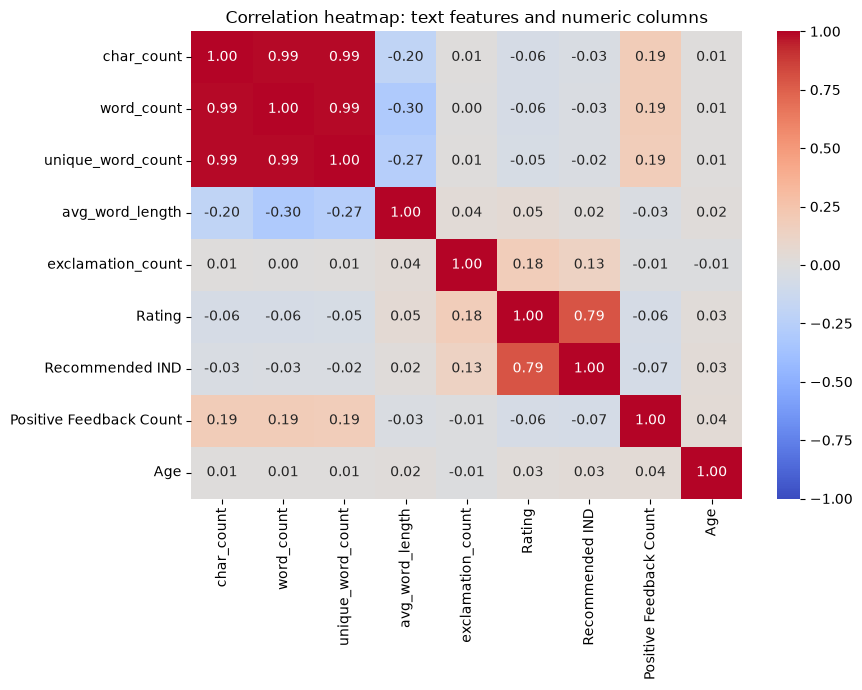

In [9]:
num_cols = ["char_count", "word_count", "unique_word_count", "avg_word_length",
            "exclamation_count", "Rating", "Recommended IND",
            "Positive Feedback Count", "Age"]
corr = df_clean[num_cols].corr()
display(corr.round(2))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap: text features and numeric columns")
plt.tight_layout()
plt.savefig("../output/figures/correlation_heatmap.png", dpi=150)
plt.show()

##### Correlation interpretation:

**Strong relationships**
- **char_count, word_count and unique_word_count are almost perfectly correlated (0.99).** This makes sense: a longer review has more characters, more words and more different words. They carry nearly the same information, so using all three together in a model would be redundant.
- **Rating and Recommended IND are strongly correlated (0.79).** Customers who give higher ratings usually recommend the item.

**Weak or moderate relationships**
- **avg_word_length vs word_count (-0.30), and vs unique_word_count (-0.27):** moderately negative. Longer reviews tend to use slightly shorter words on average, probably because people write more casually when they write more.
- **Positive Feedback Count vs review length (0.19):** weakly positive. Longer reviews get slightly more helpful votes, maybe because they contain more detail.
- **exclamation_count vs Rating (0.18) and Recommended IND (0.13):** weakly positive. Happier customers use a few more exclamation marks.

**Almost no relationship**
- Review length vs Rating (-0.06) and Recommended IND (-0.03): how long a review is says almost nothing about how happy the customer was.
- Age is close to 0 with everything, so a customer's age doesn't help explain ratings or review length in this data.

**Correlation does not imply causation.** A correlation only shows that two things move together, not that one causes the other. For example, exclamation marks are linked to higher ratings, but adding exclamation marks to a review would not make the customer happier. It's more likely that happy customers express their excitement that way. There can also be a hidden third factor behind a relationship, and correlation only measures linear relationships, so it can miss other patterns.

# II. Text Analysis

## 1. cleaned_text Column Creation

In [10]:
def clean_text(s):
    if pd.isna(s):
        return ""                                   # handle missing text
    s = s.lower().replace("’", "'")
    s = re.sub(r"https?://\S+|www\.\S+", " ", s)    # URLs
    s = s.replace("can't", "cannot").replace("won't", "will not")
    s = re.sub(r"n't\b", " not", s)                 # don't -> do not
    s = re.sub(r"'m\b", " am", s)
    s = re.sub(r"'re\b", " are", s)
    s = re.sub(r"'ve\b", " have", s)
    s = re.sub(r"'ll\b", " will", s)
    s = re.sub(r"'d\b", " would", s)
    s = re.sub(r"'s\b", "", s)
    s = re.sub(r"\d+", " ", s)                      # numbers
    s = re.sub(r"[^a-z\s]", " ", s)                 # punctuation and symbols
    s = re.sub(r"\s+", " ", s).strip()              # extra spaces
    return s

df_clean["cleaned_text"] = df_clean["Review Text"].apply(clean_text)

display(df_clean[["Review Text", "cleaned_text"]].head(5))
print("Empty cleaned_text rows:", (df_clean["cleaned_text"] == "").sum())

,Review Text,cleaned_text
0,Absolutely wonderful - silky and sexy and comf...,absolutely wonderful silky and sexy and comfor...
1,Love this dress! it's sooo pretty. i happene...,love this dress it sooo pretty i happened to f...
2,I had such high hopes for this dress and reall...,i had such high hopes for this dress and reall...
3,"I love, love, love this jumpsuit. it's fun, fl...",i love love love this jumpsuit it fun flirty a...
4,This shirt is very flattering to all due to th...,this shirt is very flattering to all due to th...


Empty cleaned_text rows: 0


#### What was did to create cleaned_text:

I created a new column called cleaned_text and left the original Review Text unchanged. The cleaning steps are:

- **Missing text:** a missing review becomes an empty string. After the earlier cleaning there are none, and the check shows 0 empty rows.
- **Lowercase:** so "Love" and "love" count as the same word.
- **URLs:** removed, in case any review contains a link.
- **Contractions expanded:** "don't" becomes "do not", "can't" becomes "cannot", "I'm" becomes "i am". This keeps negations like "not" as their own word instead of losing them when punctuation is removed.
- **Numbers and punctuation:** removed, so only letters remain.
- **Extra spaces:** collapsed into single spaces.

Why: this makes word forms consistent, so counting words and TF-IDF later treat "Love", "love!" and "love," as one token. One small side effect is that removing "'s" turns "it's" into "it".

## 2. Tokenization Statistics

In [11]:
df_clean["tokens"] = df_clean["cleaned_text"].str.split()
all_tokens = [t for toks in df_clean["tokens"] for t in toks]

print("Total tokens:", len(all_tokens))
print("Unique words:", len(set(all_tokens)))
print("Average words per record:", round(df_clean["tokens"].str.len().mean(), 1))

Total tokens: 1366598
Unique words: 13595
Average words per record: 60.4


#### Tokenization results:

I split every cleaned review into words (tokens) using spaces.

- Total tokens: 1,366,598
- Unique words (vocabulary): 13,595
- Average words per review: 60.4

**Interpretation:** the 22,627 reviews contain about 1.37 million words, but only 13,595 are different, which is about 1% of the total. So customers repeat a small, common vocabulary (dress, fit, size, love...). The average of 60.4 words is slightly higher than the 60.2 from word_count earlier, because expanding contractions turned some single words into two ("don't" became "do not").

## 3. Most Frequent 20 Words (before and after stopword removal)

,Rank,Word (with stopwords),Count,Word (no stopwords),Count
0,1,the,76160,dress,10567
1,2,i,67047,love,8942
2,3,it,49274,size,8771
3,4,and,48991,fit,7322
4,5,a,43114,like,7148
5,6,is,31141,wear,6434
6,7,this,25758,great,6114
7,8,to,24575,just,5604
8,9,in,20751,fabric,4797
9,10,not,17066,small,4726


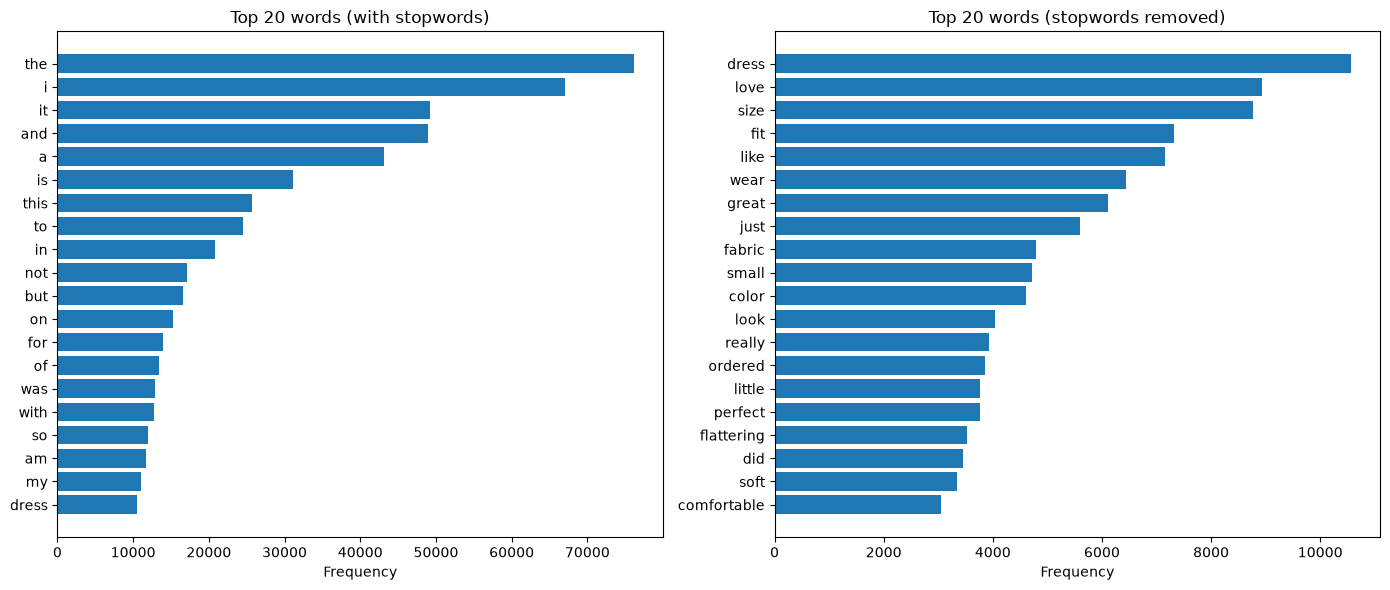

In [12]:
stop = set(ENGLISH_STOP_WORDS)
tokens_nostop = [t for t in all_tokens if t not in stop and len(t) > 2]

top_all = Counter(all_tokens).most_common(20)
top_nostop = Counter(tokens_nostop).most_common(20)

table = pd.DataFrame({
    "Rank": range(1, 21),
    "Word (with stopwords)": [w for w, _ in top_all], "Count ": [c for _, c in top_all],
    "Word (no stopwords)": [w for w, _ in top_nostop], "Count": [c for _, c in top_nostop]})
display(table)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, data, title in [(axes[0], top_all, "Top 20 words (with stopwords)"),
                        (axes[1], top_nostop, "Top 20 words (stopwords removed)")]:
    words_, counts_ = zip(*data)
    ax.barh(words_[::-1], counts_[::-1])
    ax.set_title(title)
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.savefig("../output/figures/word_frequency.png", dpi=150)
plt.show()

#### Most frequent words:

**With stopwords:** 19 of the top 20 words are stopwords (the, i, it, and, a, is, this, to...). The only real content word is "dress" at rank 20. "am" and "not" appear because I expanded "I'm" and "don't". This list tells us almost nothing about what customers talk about.

**After removing stopwords:** the list becomes meaningful: dress (10,567), love (8,942), size (8,771), fit (7,322), like (7,148), wear (6,434), great (6,114). The words fall into three themes: the product (dress, fabric, color), sizing (size, fit, small, little), and opinion (love, great, perfect, flattering, soft, comfortable).

So removing stopwords is necessary for word-frequency analysis. I used scikit-learn's stopword list and also dropped words with 2 letters or fewer.

## 4. Recommended Vs Not recommended

,reviews,avg_chars,avg_words
recommended_label,,,
Not recommended,4101,318.3,62.0
Recommended,18526,306.6,59.8


,Recommended,Not recommended
1,dress (8591),dress (1976)
2,love (8014),like (1780)
3,size (7561),fit (1327)
4,fit (5995),just (1252)
5,wear (5678),fabric (1245)
6,great (5584),size (1210)
7,like (5368),did (1001)
8,just (4352),look (965)
9,color (3887),love (928)
10,small (3816),small (910)


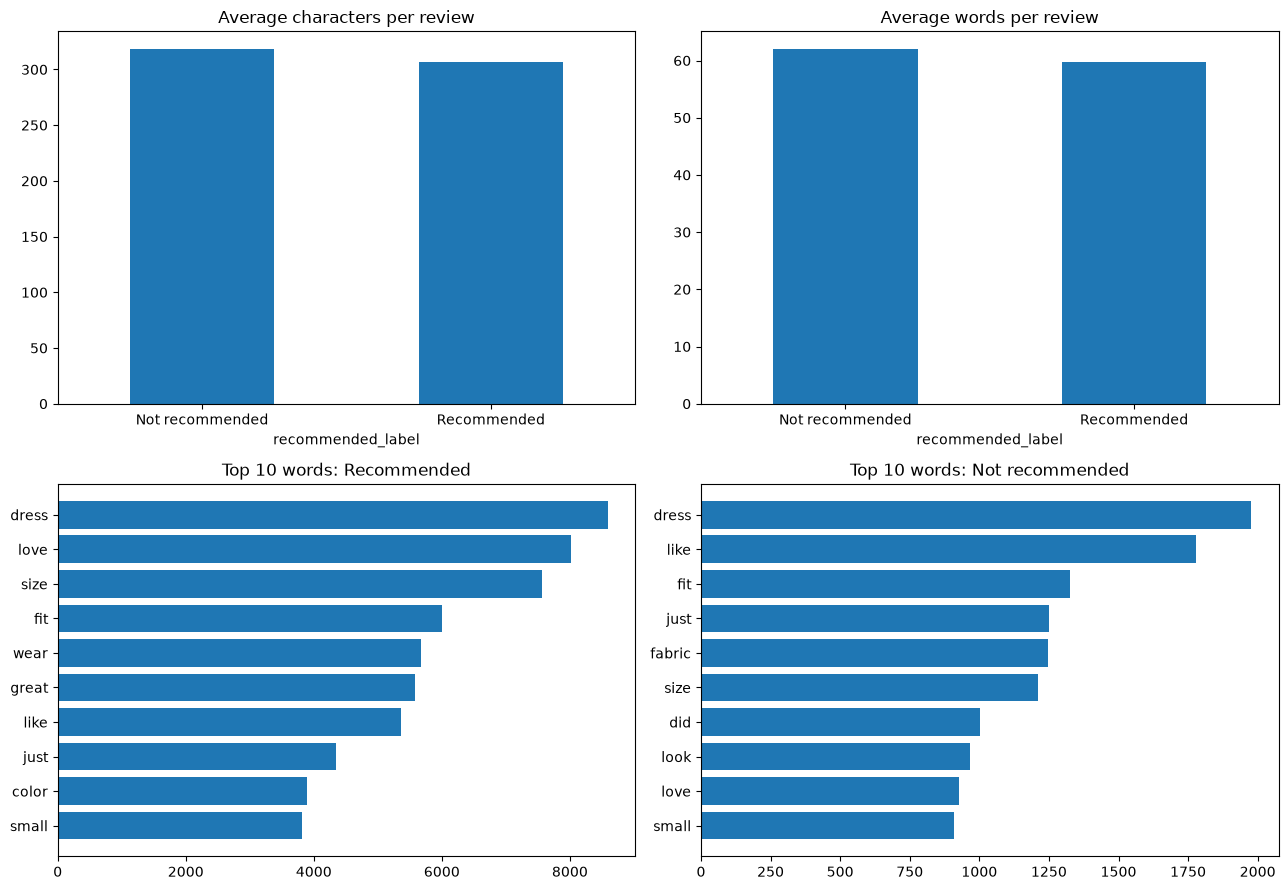

In [13]:
summary = df_clean.groupby("recommended_label").agg(
    reviews=("char_count", "size"),
    avg_chars=("char_count", "mean"),
    avg_words=("word_count", "mean")).round(1)
display(summary)

def top_words(group, n=10):
    toks = [t for row in df_clean.loc[df_clean["recommended_label"] == group, "tokens"]
            for t in row if t not in stop and len(t) > 2]
    return Counter(toks).most_common(n)

top_rec = top_words("Recommended")
top_not = top_words("Not recommended")
display(pd.DataFrame({"Recommended": [f"{w} ({c})" for w, c in top_rec],
                      "Not recommended": [f"{w} ({c})" for w, c in top_not]},
                     index=range(1, 11)))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
summary["avg_chars"].plot.bar(ax=axes[0, 0], rot=0, title="Average characters per review")
summary["avg_words"].plot.bar(ax=axes[0, 1], rot=0, title="Average words per review")
for ax, data, title in [(axes[1, 0], top_rec, "Top 10 words: Recommended"),
                        (axes[1, 1], top_not, "Top 10 words: Not recommended")]:
    w_, c_ = zip(*data)
    ax.barh(w_[::-1], c_[::-1])
    ax.set_title(title)
plt.tight_layout()
plt.savefig("../output/figures/group_comparison.png", dpi=150)
plt.show()

In [14]:
def rate(word, group):
    rows = df_clean.loc[df_clean["recommended_label"] == group, "tokens"]
    return sum(r.count(word) for r in rows) / len(rows)

words_to_check = ["love", "great", "like", "fabric", "did", "fit"]
rates = pd.DataFrame({w: {"Recommended": rate(w, "Recommended"),
                          "Not recommended": rate(w, "Not recommended")}
                      for w in words_to_check}).T.round(2)
display(rates)

,Recommended,Not recommended
love,0.43,0.23
great,0.30,0.13
like,0.29,0.43
fabric,0.19,0.30
did,0.13,0.24
fit,0.32,0.32


#### Recommended vs Not recommended

| | Reviews | Avg characters | Avg words |
|---|---|---|---|
| Recommended | 18,526 (81.9%) | 306.6 | 59.8 |
| Not recommended | 4,101 (18.1%) | 318.3 | 62.0 |

**Top 10 words (stopwords removed)**
- Recommended: dress, love, size, fit, wear, great, like, just, color, small
- Not recommended: dress, like, fit, just, fabric, size, did, look, love, small

Not recommended reviews are slightly longer (about 12 characters and 2 words more, around 4%). Since the Recommended group is about 4.5 times bigger, I compare how often a word appears per review, not its raw count.

### Insights

**Insight 1: Stopwords hide the real content**
- Observation: the most common words are not informative.
- Evidence: 19 of the top 20 words are stopwords, led by "the" (76,160) and "i" (67,047). After removal the top words are dress (10,567), love (8,942) and size (8,771).
- Interpretation: stopword removal is needed to see what customers actually discuss, though it should be used with care for tasks where small words carry meaning.

**Insight 2: Customers mostly talk about fit and sizing**
- Observation: size-related words are among the most common.
- Evidence: size (8,771), fit (7,322), small (4,726), little (3,773), and "small" is in the top 10 of both groups.
- Interpretation: sizing is the main practical concern in online clothing reviews, which is expected since buyers can't try the item on first.

**Insight 3: The vocabulary is mostly positive**
- Observation: positive words dominate the frequency list.
- Evidence: love (8,942), great (6,114), perfect (3,772), flattering (3,520), soft (3,335), comfortable (3,058). This matches the dataset, where 81.9% of reviews are recommended.
- Interpretation: the language reflects the imbalance in the data, so a model could learn mostly positive patterns. This is one reason to look at precision and recall, not just accuracy.

**Insight 4: The two groups use different words, but some words are shared**
- Observation: "love" and "great" are far more common in recommended reviews, while "like", "fabric" and "did" are more common in not recommended ones.
- Evidence (per review): love 0.43 vs 0.23, great 0.30 vs 0.13, like 0.29 vs 0.43, fabric 0.19 vs 0.30, did 0.13 vs 0.24. "fit" is equal in both (0.32).
- Interpretation: unhappy customers talk about the fabric and about what "did not" work (our cleaning turned "didn't" into "did not", so "did" is mostly a negation). "love" still appears in the not recommended top 10, and "not" is removed as a stopword, so single words can mislead ("did not love" looks positive). This is why phrases (n-grams) could help the classifier later.

**Insight 5: Review length barely differs between the groups**
- Observation: not recommended reviews are only slightly longer.
- Evidence: 318.3 vs 306.6 characters and 62.0 vs 59.8 words, which matches the near-zero correlation between length and Recommended IND (-0.03).
- Interpretation: unhappy customers explain a little more, but length alone is not a useful signal. Also, about 22.5% of reviews are over 480 characters and the maximum is 508, so a cutoff at roughly 500 characters may hide longer complaints and understate the difference.

# III. Machine Learning

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

### 1. train/test split

In [16]:
X = df_clean["cleaned_text"]
y = df_clean["Recommended IND"]      # 1 = recommended, 0 = not recommended

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", len(X_train), "| Test:", len(X_test))
print("Recommended share -> train: %.1f%% | test: %.1f%%"
      % (y_train.mean() * 100, y_test.mean() * 100))

baseline = max(y_test.mean(), 1 - y_test.mean())
print("Baseline accuracy (always predict 'Recommended'): %.3f" % baseline)

Train: 18101 | Test: 4526
Recommended share -> train: 81.9% | test: 81.9%
Baseline accuracy (always predict 'Recommended'): 0.819


##### Train/test split:

- **Target:** Recommended IND (1 = recommended, 0 = not recommended). **Input:** cleaned_text.
- I split the data 80/20: 18,101 reviews for training and 4,526 for testing, with a fixed random seed (42) so the result is reproducible.
- The split is **stratified**, so both sets keep the same class balance (81.9% recommended in train and in test). Without stratification, the smaller class could be split unevenly by chance.
- **Baseline:** a model that always says "Recommended" would already get 81.9% accuracy. So accuracy alone is not impressive here, and I also look at precision, recall and F1.

## a. Supervised Text Classification

### 2. TF-IDF

In [17]:
tfidf = TfidfVectorizer(min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)   # learn vocabulary + weights from TRAIN only
X_test_tfidf = tfidf.transform(X_test)         # just apply them to the test set

print("TF-IDF matrix (train):", X_train_tfidf.shape)
print("TF-IDF matrix (test): ", X_test_tfidf.shape)

TF-IDF matrix (train): (18101, 7168)
TF-IDF matrix (test):  (4526, 7168)


##### TF-IDF:

TF-IDF turns each review into a vector of numbers. A word gets a high weight if it appears often in that review (term frequency), but its weight is reduced if it appears in many reviews (inverse document frequency). So very common words like "dress" count for less, and distinctive words like "disappointed" count for more.

- `min_df=2` ignores words that appear in only one review. This leaves 7,168 features, compared to 13,595 unique words before.
- The vectorizer was **fitted on the training set only** and then applied to the test set. If it were fitted on all the data, information from the test set would leak into training and the results would look better than they really are.
- I kept stopwords on purpose, because words like "not" matter for sentiment ("not comfortable").

### 3. Logistic Regression Training & Evaluation

In [18]:
lr = LogisticRegression(max_iter=1000, random_state=SEED)
lr.fit(X_train_tfidf, y_train)
pred = lr.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Precision (Recommended):", round(precision_score(y_test, pred), 4))
print("Recall (Recommended):", round(recall_score(y_test, pred), 4))
print("F1 (Recommended):", round(f1_score(y_test, pred), 4))
print()
print(classification_report(y_test, pred, target_names=["Not recommended", "Recommended"]))

Accuracy: 0.8911
Precision (Recommended): 0.9052
Recall (Recommended): 0.9684
F1 (Recommended): 0.9357

                 precision    recall  f1-score   support

Not recommended       0.79      0.54      0.64       820
    Recommended       0.91      0.97      0.94      3706

       accuracy                           0.89      4526
      macro avg       0.85      0.75      0.79      4526
   weighted avg       0.88      0.89      0.88      4526



##### Logistic Regression results:

| Metric | Value |
|---|---|
| Accuracy | 0.8911 |
| Precision (Recommended) | 0.9052 |
| Recall (Recommended) | 0.9684 |
| F1 (Recommended) | 0.9357 |
| Precision / Recall / F1 (Not recommended) | 0.79 / 0.54 / 0.64 |

**Interpretation**
- Accuracy is 89.1%, about 7 points above the 81.9% baseline, so the model learned real patterns from the text.
- The model is very good at the Recommended class (recall 0.97): it finds almost all recommended reviews.
- It is much weaker on the Not recommended class: it only catches 54% of them (recall 0.54), though when it does say "Not recommended" it is right 79% of the time (precision 0.79).
- The macro average F1 (0.79) is lower than the weighted one (0.88) because the weighted average is dominated by the big class. This is why accuracy alone looks better than the model really is.

### 4. Confusion Matrix Generation

[[ 444  376]
 [ 117 3589]]


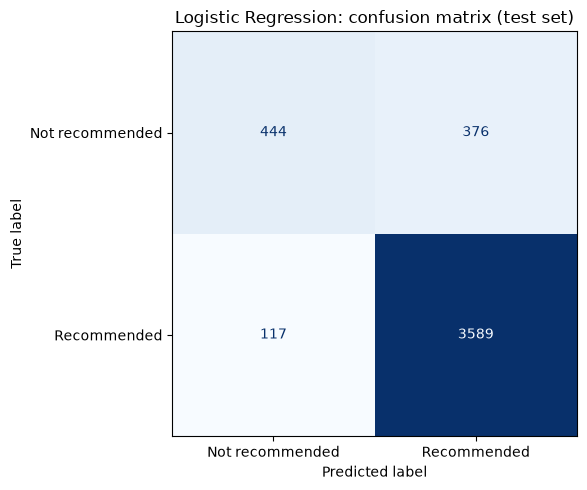

In [19]:
cm = confusion_matrix(y_test, pred)
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Not recommended", "Recommended"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Logistic Regression: confusion matrix (test set)")
plt.tight_layout()
plt.savefig("../output/figures/confusion_matrix.png", dpi=150)
plt.show()

##### Confusion matrix:

| | Predicted: Not recommended | Predicted: Recommended |
|---|---|---|
| **Actual: Not recommended** | 444 (true negatives) | 376 (false positives) |
| **Actual: Recommended** | 117 (false negatives) | 3,589 (true positives) |

- The model got 444 + 3,589 = 4,033 of 4,526 reviews right.
- The most common mistake is predicting "Recommended" for a review that was actually not recommended (376 cases). That is 46% of all the not recommended reviews in the test set.
- The opposite mistake is much rarer: 117 recommended reviews were predicted as not recommended (about 3% of that class).
- So the model leans toward the majority class, which is expected when one class is four times bigger than the other.

In [20]:
# which words drive the model
names = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
print("Words pushing toward NOT recommended:", list(names[order[:15]]))
print("Words pushing toward RECOMMENDED:    ", list(names[order[-15:]][::-1]))

Words pushing toward NOT recommended: ['disappointed', 'returning', 'wanted', 'returned', 'cheap', 'was', 'not', 'unflattering', 'huge', 'back', 'looked', 'poor', 'bad', 'excited', 'were']
Words pushing toward RECOMMENDED:     ['love', 'perfect', 'comfortable', 'great', 'little', 'with', 'perfectly', 'fits', 'compliments', 'soft', 'unique', 'bit', 'nicely', 'can', 'size']


##### Words that drive the model:

- **Towards Not recommended:** disappointed, returning, returned, cheap, unflattering, huge, poor, bad, not, back. These make sense: they describe returns, bad quality, and bad fit.
- **Towards Recommended:** love, perfect, comfortable, great, perfectly, fits, compliments, soft, nicely. These are clearly positive words.
- "not" is a strong sign for Not recommended, which confirms that keeping stopwords was a good decision.
- Some words look odd but have a likely explanation. "was", "were", "wanted", "looked" and "excited" push towards Not recommended, probably because unhappy customers tell a story in the past tense ("I was so excited, but it looked cheap"). "little", "bit" and "size" push towards Recommended, probably from phrases like "a little", "a bit" and "true to size".

In [21]:
# save model_metrics.txt
with open("../output/model_metrics.txt", "w") as f:
    f.write("Supervised model: TF-IDF + Logistic Regression\n")
    f.write("Target: Recommended IND (1 = recommended, 0 = not recommended)\n")
    f.write(f"Train size: {len(X_train)} | Test size: {len(X_test)}\n")
    f.write(f"Baseline accuracy (majority class): {baseline:.4f}\n\n")
    f.write(f"Accuracy: {accuracy_score(y_test, pred):.4f}\n")
    f.write(f"Precision (Recommended): {precision_score(y_test, pred):.4f}\n")
    f.write(f"Recall (Recommended): {recall_score(y_test, pred):.4f}\n")
    f.write(f"F1 (Recommended): {f1_score(y_test, pred):.4f}\n\n")
    f.write(classification_report(y_test, pred, target_names=["Not recommended", "Recommended"]))
    f.write(f"\nConfusion matrix [[TN, FP], [FN, TP]]:\n{cm}\n")

## BONUS: Comparing two Supervised Classifiers

In [22]:
def run(name, model):
    model.fit(X_train_tfidf, y_train)
    p = model.predict(X_test_tfidf)
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, p),
            "Precision (Rec.)": precision_score(y_test, p),
            "Recall (Rec.)": recall_score(y_test, p),
            "F1 (Rec.)": f1_score(y_test, p),
            "Recall (Not rec.)": recall_score(y_test, p, pos_label=0),
            "F1 (Not rec.)": f1_score(y_test, p, pos_label=0)}

results = pd.DataFrame([
    run("Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED)),
    run("Multinomial Naive Bayes", MultinomialNB()),
]).round(4)
display(results)

with open("../output/model_metrics.txt", "a") as f:
    f.write("\n\nModel comparison (bonus)\n")
    f.write(results.to_string(index=False))

,Model,Accuracy,Precision (Rec.),Recall (Rec.),F1 (Rec.),Recall (Not rec.),F1 (Not rec.)
0,Logistic Regression,0.8911,0.9052,0.9684,0.9357,0.5415,0.6430
1,Multinomial Naive Bayes,0.8343,0.8320,0.9995,0.9081,0.0878,0.1611


##### Comparing the two classifiers:

| Model | Accuracy | F1 (Recommended) | Recall (Not rec.) | F1 (Not rec.) |
|---|---|---|---|---|
| Logistic Regression | 0.8911 | 0.9357 | 0.5415 | 0.6430 |
| Multinomial Naive Bayes | 0.8343 | 0.9081 | 0.0878 | 0.1611 |

- **Logistic Regression is clearly better.** It has higher accuracy and, more importantly, it is much better on the minority class.
- Naive Bayes got 99.95% recall on Recommended but only 8.8% on Not recommended: it predicts "Recommended" almost every time. Its accuracy (83.4%) is only about 1.5 points above the 81.9% baseline, so it is barely better than guessing the majority class.
- Possible reasons: Logistic Regression learns a weight for each word and handles the class imbalance better, while Naive Bayes is simpler, assumes words are independent, and leans heavily towards the most common class.

### Overall interpretation and limitations

TF-IDF with Logistic Regression predicts whether a customer recommends a product from the review text with 89.1% accuracy, clearly above the 81.9% baseline, and the words the model relies on make sense.

**Limitations**
- **Class imbalance:** only 18% of reviews are Not recommended, so the model finds just 54% of them. Accuracy hides this. Using class weights, tuning the decision threshold, or collecting more negative reviews could help.
- **No word order:** TF-IDF treats each word separately, so "not good" and "good, not bad" can look similar. Using phrases (n-grams) could help.
- **Truncated reviews:** reviews are cut at about 500 characters, so some complaints may be missing.
- **Noisy labels:** a customer can write a positive review and still not recommend the item, or the other way around, so some errors are not the model's fault.
- **One split:** I used a single train/test split, so the scores are one estimate and could change a little with another split. The data is also from one retailer, so the model may not work as well on other products.

## b. K-Means Clustering

In [23]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

### 1. Numerical Representation (TF-IDF + dimensionality reduction)

In [24]:
tfidf_km = TfidfVectorizer(min_df=5, max_df=0.5, stop_words="english")
X_km = tfidf_km.fit_transform(df_clean["cleaned_text"])

svd = TruncatedSVD(n_components=100, random_state=SEED)
lsa = make_pipeline(svd, Normalizer(copy=False))
X_svd = lsa.fit_transform(X_km)

print("TF-IDF shape:", X_km.shape)
print("After SVD:", X_svd.shape)
print("Variance kept: %.1f%%" % (svd.explained_variance_ratio_.sum() * 100))

TF-IDF shape: (22627, 4458)
After SVD: (22627, 100)
Variance kept: 26.5%


##### Numerical representation for K-Means:

- K-Means needs numbers, so I turned each review into a TF-IDF vector again, this time using all 22,627 reviews.
- K-Means is **unsupervised**: it never sees Recommended IND, there is no train/test split, and it only groups reviews that look similar. The labels are used afterwards, just to check the result.
- Unlike the classifier, here I **removed stopwords** and words that appear in more than half of the reviews (max_df=0.5), and ignored words that appear in fewer than 5 reviews. This leaves 4,458 features. I want the groups to reflect topics, not filler words like "the" and "it".
- 4,458 sparse columns is too much for K-Means, so I used TruncatedSVD to compress them into 100 dense dimensions, then normalized each vector so distances behave like cosine similarity.
- The 100 dimensions keep only 26.5% of the variance, which is common for text because word usage is spread over many directions. It keeps the main patterns but loses some detail, which is a limitation.

### 2. Choosing Best K

,k,inertia,silhouette
0,2,19314.5917,0.0210
1,3,19018.2717,0.0227
2,4,18777.7633,0.0273
3,5,18573.2657,0.0282
4,6,18389.5272,0.0310
5,7,18173.6724,0.0346
6,8,18002.3964,0.0366
7,9,17841.7238,0.0388
8,10,17751.9783,0.0360


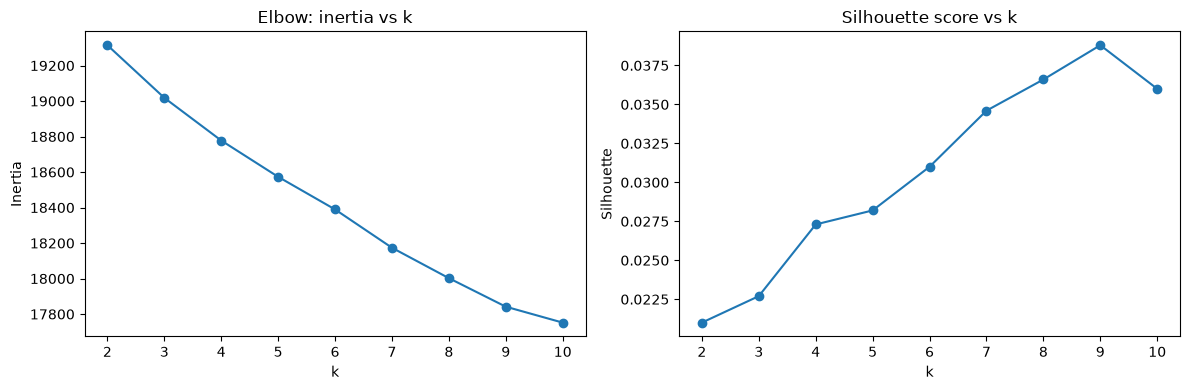

In [25]:
rows = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    lab = km_k.fit_predict(X_svd)
    rows.append({"k": k,
                 "inertia": km_k.inertia_,
                 "silhouette": silhouette_score(X_svd, lab, sample_size=5000, random_state=SEED)})
k_results = pd.DataFrame(rows).round(4)
display(k_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].set_title("Elbow: inertia vs k")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(k_results["k"], k_results["silhouette"], marker="o")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.savefig("../output/figures/kmeans_k_selection.png", dpi=150)
plt.show()

##### Choosing k Experiment:

I tried k from 2 to 10. To keep it fast, the silhouette score was calculated on a random sample of 5,000 reviews.

- **Elbow:** inertia falls smoothly from 19,315 (k=2) to 17,752 (k=10) with no sharp bend, so the elbow does not give a clear answer.
- **Silhouette:** it rises from 0.021 at k=2 to a peak of 0.0388 at k=9, then drops to 0.0360 at k=10.
- All the scores are very low (below 0.04), meaning the clusters overlap a lot. This is normal for review text, because most reviews share the same vocabulary (dress, love, size, fit).
- **I chose k = 9** because it has the best silhouette score and each cluster is easy to describe in a sentence (see below). Small values like k=2 or 3 would give vague groups. I did not pick k=3 automatically.

### 3. Final Model

In [26]:
K_FINAL = 9

km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED)
df_clean["cluster"] = km.fit_predict(X_svd)

sil = silhouette_score(X_svd, df_clean["cluster"], sample_size=5000, random_state=SEED)
sizes = df_clean["cluster"].value_counts().sort_index()

print("k =", K_FINAL)
print("Silhouette score: %.4f" % sil)
print(sizes.to_string())

k = 9
Silhouette score: 0.0388
cluster
0    4679
1    3681
2    1088
3    1320
4    4459
5    1455
6    1026
7    3524
8    1395


##### Final model: with k = 9

- Silhouette score: 0.0388 (on a 5,000-review sample).
- Cluster sizes: 0 = 4,679 | 1 = 3,681 | 2 = 1,088 | 3 = 1,320 | 4 = 4,459 | 5 = 1,455 | 6 = 1,026 | 7 = 3,524 | 8 = 1,395.
- Four clusters (0, 4, 1, 7) hold about 72% of all reviews, and the other five have between 1,026 and 1,455 reviews each.

The silhouette score goes from -1 to 1. A value near 0 means clusters overlap. 0.0388 is low but positive, so the grouping is slightly better than random, but it is not sharp. The clusters should be read as loose themes, not clearly separated groups.

#### Top terms and a Representative Review per Cluster

In [27]:
terms = np.array(tfidf_km.get_feature_names_out())
top_terms = {}

for c in range(K_FINAL):
    idx = np.where(df_clean["cluster"] == c)[0]
    mean_vec = np.asarray(X_km[idx].mean(axis=0)).ravel()
    top_terms[c] = list(terms[mean_vec.argsort()[::-1][:10]])

    dist = ((X_svd[idx] - km.cluster_centers_[c]) ** 2).sum(axis=1)
    example = df_clean["Review Text"].iloc[idx[dist.argmin()]]

    print(f"Cluster {c} ({len(idx)} reviews)")
    print("  Top terms:", ", ".join(top_terms[c]))
    print("  Closest to centre:", example[:200], "...\n")

Cluster 0 (4679 reviews)
  Top terms: love, great, comfortable, color, soft, wear, perfect, bought, fit, flattering
  Closest to centre: I immediatley bought this adorable dress after trying it on at my local retailer and absolutely love it! it fits tts for me in my regular size small (34d-27-35) and it's incredibly soft and comfortabl ...

Cluster 1 (3681 reviews)
  Top terms: dress, love, size, fit, beautiful, wear, flattering, like, just, fabric
  Closest to centre: The only negative about this dress was the placement of the stripe across your stomach ...

Cluster 2 (1088 reviews)
  Top terms: pants, love, fit, great, size, pair, comfortable, wear, like, perfect
  Closest to centre: It takes perfection for me to pay this much for a pair of pants, and these delivered! i bought these pants love-at-first-sight in the carbon color. i have not washed them yet, so i can't comment on du ...

Cluster 3 (1320 reviews)
  Top terms: jeans, great, skinny, love, fit, wear, pair, perfect, size, l

##### What each cluster represents:

| Cluster | Reviews | Top terms | My interpretation |
|---|---|---|---|
| 0 | 4,679 | love, great, comfortable, soft, perfect | Enthusiastic praise: comfortable and soft items |
| 1 | 3,681 | dress, beautiful, flattering, size, fit | Dresses |
| 2 | 1,088 | pants, pair, fit, comfortable | Pants |
| 3 | 1,320 | jeans, skinny, pair, fit | Jeans and how they fit |
| 4 | 4,459 | like, just, fabric, did, really, look | Doubts about fabric and how the item looks or fits |
| 5 | 1,455 | shirt, cute, soft, material | Shirts and tops |
| 6 | 1,026 | skirt, waist, fabric, size | Skirts |
| 7 | 3,524 | size, small, medium, large, runs, usually, xs | Sizing advice ("I usually wear a small, it runs large") |
| 8 | 1,395 | sweater, soft, warm, sleeves | Sweaters |

The example closest to each cluster's centre supports these names. For example, cluster 4's example is a review about too much fabric around the waist ("I really wanted to love this"), and cluster 7's example gives height, weight and the size the customer ordered.

#### Comparing Clusters with the Real Labels

recommended_label,Not recommended,Recommended
cluster,,
0,251,4428
1,701,2980
2,135,953
3,76,1244
4,1632,2827
5,343,1112
6,154,872
7,541,2983
8,268,1127


recommended_label,Not recommended,Recommended
cluster,,
0,5.4,94.6
1,19.0,81.0
2,12.4,87.6
3,5.8,94.2
4,36.6,63.4
5,23.6,76.4
6,15.0,85.0
7,15.4,84.6
8,19.2,80.8


,avg_rating
cluster,
0,4.65
1,4.17
2,4.38
3,4.60
4,3.58
5,3.99
6,4.26
7,4.18
8,4.19


Department Name,Bottoms,Dresses,Intimate,Jackets,Tops,Trend
cluster,,,,,,
0,13.0,14.1,12.9,7.8,52.1,0.2
1,0.6,93.4,2.8,0.3,2.0,0.9
2,69.7,0.8,11.5,1.3,16.5,0.3
3,45.3,1.2,2.3,3.5,47.3,0.5
4,11.6,20.9,8.1,5.9,53.1,0.5
5,1.7,1.6,2.7,1.4,92.4,0.0
6,69.3,15.6,1.7,1.4,10.6,1.5
7,11.7,24.3,9.8,6.2,47.3,0.7
8,0.9,3.7,2.0,3.7,89.5,0.3


Adjusted Rand Index: 0.0094 | Normalized Mutual Information: 0.0314


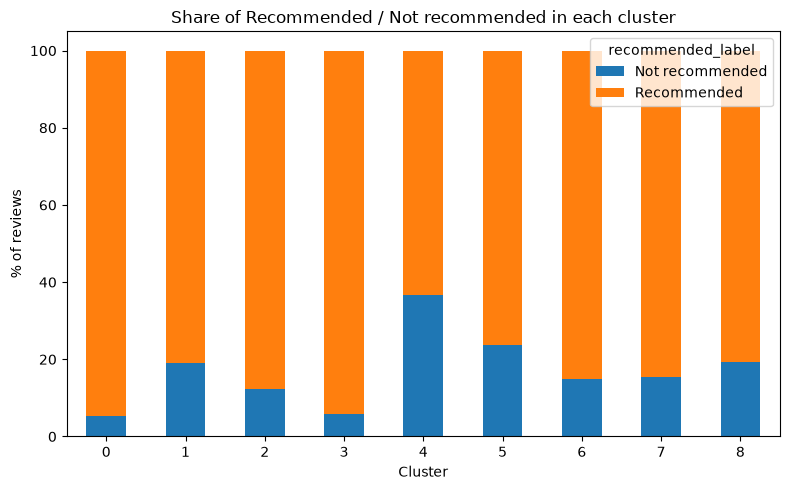

In [28]:
ct = pd.crosstab(df_clean["cluster"], df_clean["recommended_label"])
ct_pct = pd.crosstab(df_clean["cluster"], df_clean["recommended_label"], normalize="index").mul(100).round(1)
display(ct)
display(ct_pct)

display(df_clean.groupby("cluster")["Rating"].mean().round(2).to_frame("avg_rating"))
display(pd.crosstab(df_clean["cluster"], df_clean["Department Name"], normalize="index").mul(100).round(1))

ari = adjusted_rand_score(df_clean["Recommended IND"], df_clean["cluster"])
nmi = normalized_mutual_info_score(df_clean["Recommended IND"], df_clean["cluster"])
print("Adjusted Rand Index: %.4f | Normalized Mutual Information: %.4f" % (ari, nmi))

ct_pct.plot(kind="bar", stacked=True, figsize=(8, 5), rot=0)
plt.title("Share of Recommended / Not recommended in each cluster")
plt.xlabel("Cluster"); plt.ylabel("% of reviews")
plt.tight_layout()
plt.savefig("../output/figures/cluster_vs_label.png", dpi=150)
plt.show()

##### Comparing the clusters with the real labels:

| Cluster | Theme | % Recommended | Avg rating |
|---|---|---|---|
| 0 | Praise | 94.6 | 4.65 |
| 3 | Jeans | 94.2 | 4.60 |
| 2 | Pants | 87.6 | 4.38 |
| 6 | Skirts | 85.0 | 4.26 |
| 7 | Sizing | 84.6 | 4.18 |
| 1 | Dresses | 81.0 | 4.17 |
| 8 | Sweaters | 80.8 | 4.19 |
| 5 | Shirts | 76.4 | 3.99 |
| 4 | Fabric / look doubts | 63.4 | 3.58 |

**The clusters do not match the labels.** The Adjusted Rand Index is 0.0094 and the Normalized Mutual Information is 0.0314, both close to 0. This is expected: K-Means never saw the labels, and it grouped reviews by topic (garment type), not by whether the customer was happy. The department table confirms this: cluster 1 is 93% Dresses, cluster 5 is 92% Tops, cluster 8 is 90% Tops, and clusters 2 and 6 are about 70% Bottoms. Cluster 3 (jeans) is 45% Bottoms and 47% Tops, probably because many tops reviews mention wearing the top with jeans.

**But the clusters are not equal in sentiment.** The recommended share ranges from 63.4% to 94.6%, compared to 81.9% overall.
- **Cluster 4 is the "problem" cluster:** 36.6% not recommended, the lowest average rating (3.58), and it holds 1,632 of the 4,101 not recommended reviews (about 40%). Its words (fabric, did, really, look) fit complaints about fabric and fit. Still, 63% of its reviews are recommended, so it is not a clean "unhappy" group.
- **Clusters 0 and 3** are the happiest, with about 94-95% recommended and ratings above 4.6.

Cluster numbers are arbitrary, so cluster 0 does not correspond to class 0. That is why I compare distributions, not IDs.

In [29]:
interpretation = """
K-Means (k=9) mostly grouped the reviews by garment type and topic: dresses, pants, jeans, skirts, shirts, sweaters, a cluster about sizing advice, a cluster of enthusiastic praise (love, comfortable, soft), and a cluster about doubts with fabric and fit. The clusters do not match the Recommended / Not recommended labels (ARI 0.0094, NMI 0.0314), because K-Means only used text similarity and never saw the labels. Cluster 4 (fabric and fit doubts) has the most complaints: 36.6% not recommended and an average rating of 3.58, compared with 18.1% not recommended overall. The silhouette score is low (0.0388), so the clusters overlap and should be read as loose themes.
"""

with open("../output/cluster_summary.txt", "w") as f:
    f.write("K-Means clustering of review text (TF-IDF + TruncatedSVD, 100 components)\n")
    f.write(f"k = {K_FINAL}\n")
    f.write(f"Silhouette score (5,000-review sample): {sil:.4f}\n")
    f.write(f"Adjusted Rand Index vs Recommended IND: {ari:.4f} | NMI: {nmi:.4f}\n\n")
    f.write("Cluster sizes:\n")
    for c, n in sizes.items():
        f.write(f"  Cluster {c}: {n} reviews | top terms: {', '.join(top_terms[c])}\n")
    f.write("\nRecommended share per cluster (%):\n")
    f.write(ct_pct.to_string())
    f.write("\n\nInterpretation:\n")
    f.write(interpretation.strip() + "\n")

In [30]:
out = df_clean.drop(columns=["tokens"])      # tokens is a list column, not needed in the CSV
out.to_csv("../output/cleaned_data.csv", index=False)
print(out.shape)
print(out.columns.tolist())

(22627, 22)
['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name', 'age_group', 'recommended_label', 'rating_level', 'class_consolidated', 'feedback_scaled', 'char_count', 'word_count', 'unique_word_count', 'avg_word_length', 'exclamation_count', 'cleaned_text', 'cluster']
